In [ ]:
# 1 Import Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# 2 Load Dataset
df = pd.read_csv('sneakers_streetwear_sales_data.csv')
df.head()

,Date,Product Name,Product Type,Brand,Gender,Category,Country,Quantity,Unit Price ($),Amount ($),Payment Mode
0,2022-05-27,Fear of God Essentials Tee,T-shirt,Essentials,Unisex,Limited Edition,Japan,5,141.82,709.10,Card
1,2022-08-22,Yeezy Boost 350,Sneakers,Adidas,Unisex,Streetwear,USA,2,267.34,534.68,Cash on Delivery
2,2022-04-03,Nike Dunk Low,Sneakers,Nike,Women,Limited Edition,Germany,1,292.00,292.00,Cash on Delivery
3,2022-07-13,Nike Tech Fleece,Hoodie,Nike,Men,Limited Edition,USA,4,245.44,981.76,Cash on Delivery
4,2022-08-25,Jordan 1 High,Sneakers,Nike,Women,Casual,Australia,2,184.51,369.02,Cash on Delivery


In [ ]:
# 3 Data Cleaning
df.dropna(subset=['Product Name'], inplace=True)
df = df[df['Quantity'] > 0]
df['Date'] = pd.to_datetime(df['Date'])
df['TotalPrice'] = df['Quantity'] * df['Unit Price ($)']

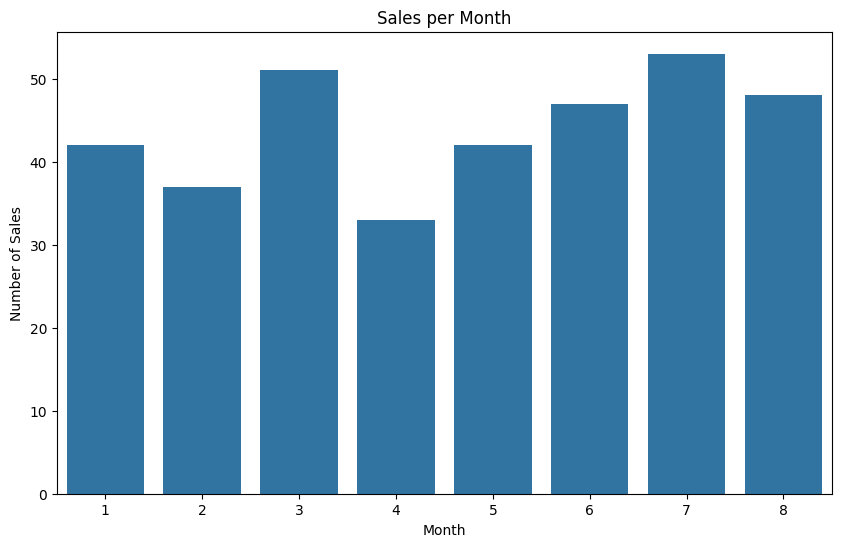

In [ ]:
# 4 Exploratory Analysis
sales_per_month = df.groupby(df['Date'].dt.month).size()
plt.figure(figsize=(10, 6))
sns.barplot(x=sales_per_month.index, y=sales_per_month.values)
plt.title('Sales per Month')
plt.xlabel('Month')
plt.ylabel('Number of Sales')
plt.show()

In [ ]:
# 5 RFM Segmentation
snapshot_date = df['Date'].max() + dt.timedelta(days=1)
rfm = df.groupby('Product Type').agg({
    'Date': lambda x: (snapshot_date - x.max()).days,
    'Amount ($)': ['count', 'sum']  # Aggregate both count and sum
})
rfm.columns = ['Recency', 'Frequency', 'Monetary'] # Rename columns after aggregation

In [ ]:
# Quantile segmentation
rfm['R_Score'] = pd.qcut(rfm['Recency'].rank(method='first'), 4, labels=[4,3,2,1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1,2,3,4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 4, labels=[1,2,3,4])
rfm['RFM_Segment'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

In [ ]:
# 6 Insight Example
top_customers = rfm.sort_values('Monetary', ascending=False).head(10)
print(top_customers)

              Recency  Frequency  Monetary R_Score F_Score M_Score RFM_Segment
Product Type                                                                  
Sneakers            1        136  81586.89       4       4       4         444
Hoodie              2        121  63109.45       4       3       3         433
Joggers             2         41  21342.02       3       2       2         322
Cap                26         29  13915.46       1       1       1         111
T-shirt             2         26  13149.25       2       1       1         211
